# Tune metadata models with separate patient checks: deduplicated Subset data

Does choosing model settings within training data improve predictions for held-out patients? We return to the spline and tree models in [05_metadata_models.ipynb](05_metadata_models.ipynb) and add the metadata NN from [06_metadata_neural_network.ipynb](06_metadata_neural_network.ipynb), using age, sex and anatomical site, the metadata alongside each image.

The computed results below compare fixed and selected versions of all four model families. The NN extension adds a prescribed 36-recipe search of hidden-layer size, learning rate and dropout. Results remain development evidence; the reserved test is not used.

For metric definitions, see the [short concept guide](../concepts.md).


**Scope and preservation:** this notebook uses the complete archived original as its section and visual template. Numerical findings are computed from the explicitly identified versioned run. The original experiments remain archived; no reserved-test labels or final all-development fit are used here.

## Context and methods

Tuning searches settings that control a model's flexibility. Selecting them on the same patients used to report performance could favour lucky choices. Nested cross-validation separates these roles with two levels of patient groups, or folds.

For each of five outer folds, reserve its patients for assessment. Use three preserved inner patient folds within the other patients, keeping each patient together. Compare settings on those inner groups, choose the highest mean AP and fit on all outer-training patients. Predict the outer group once. This evaluates the selection procedure, whose chosen settings can differ between folds.

The spline tries 18 combinations of regularisation, knots and degree. Regularisation restrains fitting; knots and degree control the age curve's shape. Each tree method tries 12 combinations. Every search includes the original settings, and all preprocessing is fitted within training.

Average precision (AP) is primary because it rewards ranking rare malignant images near the top. ROC-AUC measures how often a malignant image scores above a benign one; 0.5 is chance. Higher is better for both. Log loss and Brier score measure probability error; lower is better.

The outer folds have guided earlier model choices. Nested selection prevents direct use of their labels in their own search, but these remain development results rather than independent final-test evidence.


**Experiment-scope addition:** the NN now receives its own 36-recipe search, after the fixed NN comparison in stage 06. The selected method is the three-seed average, not the best individual seed. **Aggregation clarification:** mean outer-fold AP is the primary selection-procedure comparison; pooled scores and curves are secondary descriptive views.

## Data

### 1. Set paths and imports

Use the frozen retained-development manifest and preserved Subset folds and project Python kernel. Output paths identify the saved tables and figures. Re-executing this report reads completed receipts and writes only presentation copies inside the new versioned run. The separate runner performs the searches; legacy named outputs are never overwritten.


In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

PROJECT_ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
                    if (path / "src" / "melanoma_detection").exists())
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))
from melanoma_detection.metadata_nn_tuning_reporting import (
    load_tuning, render_section, plot_nn_comparison, plot_tuning_bars, plot_tuning_curves)
plt.rcdefaults()

ORIGINAL_EXPORT_DPI = 320
NN_COMPARISON_COLORS = ['#2563EB', '#D97706', '#D97706', '#D97706', '#303030']
report = load_tuning(PROJECT_ROOT, 'dedup_v1', run_id='nn_grid36_v1')
report["export_dpi"] = ORIGINAL_EXPORT_DPI
display(Markdown("**Saved-results report:** " + report["status"] +
                 ". Executing cells verifies and presents artifacts; training runs separately."))


C:\Users\thoma\Documents\GitHub\ADS2002-Melanoma\src\melanoma_detection\metadata_nn_tuning_reporting.py:127: DtypeWarning: Columns (0: provenance) have mixed types. Specify dtype option on import or set low_memory=False.
  artifacts[name] = pd.read_csv(source,float_precision="round_trip")


**Saved-results report:** complete. Executing cells verifies and presents artifacts; training runs separately.

### 2. Load and check the development data

Confirm that the required fields and five folds are present and every patient's images stay in one outer fold. The counts below should match the earlier metadata notebooks, allowing us to compare the methods on the same data.


In [2]:
render_section(report, 'inputs')

,images,patients,malignant_images
fold,,,
0,1344,84,24
1,1366,84,26
2,1328,87,26
3,1371,82,25
4,1297,85,26


Verified **6,706 development images**, **422 patients**, **127 malignant images** (1.89%); condition `dedup_v1`, run `nn_grid36_v1`. All declared output hashes match. Reserved-test loading and final fitting are recorded false.

### Check the preserved inner patient groups

Compare fitting and inner-assessment patient counts, malignant support and overlap checks. The NN adds a third role: training-only stopping patients choose epoch count inside the inner fitting pool. This prevents the labels used to assess a candidate from also choosing its training duration. The clean condition filters original memberships; it does not rebuild folds after removing copies.

In [3]:
render_section(report, 'tuning_memberships')

,outer_fold,inner_fold,fit_images,validation_images,fit_patients,validation_patients,fit_positive_images,validation_positive_images,patient_overlap,outer_patient_overlap,condition,provenance
0,0,0,3528,1834,225,113,70,33,0,0,dedup_v1,reused_clean_classical
1,0,1,3658,1704,227,111,68,35,0,0,dedup_v1,reused_clean_classical
2,0,2,3538,1824,224,114,68,35,0,0,dedup_v1,reused_clean_classical
3,1,0,3528,1812,225,113,66,35,0,0,dedup_v1,reused_clean_classical
4,1,1,3634,1706,225,113,69,32,0,0,dedup_v1,reused_clean_classical
5,1,2,3518,1822,226,112,67,34,0,0,dedup_v1,reused_clean_classical
6,2,0,3564,1814,226,109,67,34,0,0,dedup_v1,reused_clean_classical
7,2,1,3602,1776,224,111,68,33,0,0,dedup_v1,reused_clean_classical
8,2,2,3590,1788,220,115,67,34,0,0,dedup_v1,reused_clean_classical
9,3,0,3532,1803,226,114,68,34,0,0,dedup_v1,reused_clean_classical


,outer_fold,inner_fold,base_seed,epoch_fit_images,epoch_stop_images,refit_images,score_images,epoch_fit_patients,epoch_stop_patients,refit_patients,score_patients
15,0,0,42,1824,1704,3528,1834,114,111,225,113
16,0,0,142,1704,1824,3528,1834,111,114,225,113
17,0,0,242,1824,1704,3528,1834,114,111,225,113
18,0,1,42,1834,1824,3658,1704,113,114,227,111
19,0,1,142,1824,1834,3658,1704,114,113,227,111
20,0,1,242,1834,1824,3658,1704,113,114,227,111
21,0,2,42,1704,1834,3538,1824,111,113,224,114
22,0,2,142,1834,1704,3538,1824,113,111,224,114
23,0,2,242,1704,1834,3538,1824,111,113,224,114
342,1,0,42,1822,1706,3528,1812,112,113,225,113


Inner patient membership was reconstructed from the original row order using the original seed rule, then retained for the original run and filtered for the clean run. The historical notebook did not save a membership receipt; the reconstruction and current membership hashes make that qualification explicit. Fitting, stopping and assessment patients have separate roles; the outer assessment group stays outside all inner roles.

### 3. Define the model pipelines

Each pipeline includes both preprocessing and the model. A fresh training fit learns its own age transformation and category columns. This prevents validation patients from influencing the features used during their model's fitting.


In [4]:
render_section(report, 'tuning_grid')

,model,parameter,tried_values,recipes
0,random_forest,max_depth,"4, 8, None",12
1,random_forest,max_features,"1.0, sqrt",12
2,random_forest,min_samples_leaf,"15, 5",12
3,spline,C,"0.1, 1.0, 10.0",18
4,spline,degree,"2, 3",18
5,spline,n_knots,"3, 4, 5",18
6,xgboost,learning_rate,"0.03, 0.05, 0.1",12
7,xgboost,max_depth,"2, 3",12
8,xgboost,min_child_weight,"1, 5",12


,recipe_id,recipe_order,hidden_units,learning_rate,dropout
0,r00,0,32,0.0010,0.2
1,r01,1,8,0.0003,0.0
2,r02,2,8,0.0003,0.2
3,r03,3,8,0.0003,0.4
4,r04,4,8,0.0010,0.0
5,r05,5,8,0.0010,0.2
6,r06,6,8,0.0010,0.4
7,r07,7,8,0.0030,0.0
8,r08,8,8,0.0030,0.2
9,r09,9,8,0.0030,0.4


The NN search contains **36 recipes** in each outer-training selection. Each recipe is assessed through the equal three-seed ensemble on three inner patient folds. Inner assessment labels choose settings; disjoint stopping patients choose duration. Neither role uses that run's outer assessment patients.

### Explain the neural-network settings being searched

The hidden layer combines the encoded age, sex and site inputs with learned weights. We compare 8, 16, 32 and 64 units. A larger layer can express more interactions, but has more parameters relative to the few malignant patients. A smaller layer may miss useful patterns; increasing size is therefore a question for held-out training groups, not an automatic improvement.

AdamW's learning rate controls the size of each weight update. Rates 0.0003, 0.001 and 0.003 compare slower, baseline and faster steps. Too small a rate may not reach a useful solution within the epoch cap; too large a rate may overshoot or fluctuate. Early stopping cannot fully replace this setting because it controls duration, rather than the update size.

Dropout randomly masks hidden activations during training. Rates 0, 0.2 and 0.4 compare no masking, the fixed baseline and stronger masking. It can reduce reliance on individual units but may also weaken a small network. Prediction always disables dropout. The Cartesian product gives 4 × 3 × 3 = 36 recipes, including the existing 32/0.001/0.2 procedure. Weight decay remains 0.001; depth, batch size 128, ReLU, unweighted binary cross-entropy and the epoch cap remain fixed.

For each candidate and inner assessment fold, separate inner-training patients choose duration through a stopping split. Preprocessing is learned only on fitting patients for that choice. A fresh preprocessor and network then refit on all inner-training patients for the selected duration and predict the disjoint inner assessment patients. The three prescribed seed predictions are averaged before AP is computed. The recipe with highest mean AP across the three inner assessment folds wins; deterministic recipe order resolves ties. A fresh selected procedure predicts outer patients once. The outer labels neither choose duration nor select settings.

The stopping split is prescribed rather than searched. For inner assessment group v, the remaining groups are [(v+1)%3, (v+2)%3]. Seed indices 0 and 2 stop on the first and fit on the second; index 1 reverses these roles. For example, assessing group 0 leaves groups 1 and 2: seeds 42 and 242 stop on group 1, while seed 142 stops on group 2. The fresh inner refit uses both groups before predicting group 0. Exact recipe ties prefer the current 32/0.001/0.2 setting, then ascending size, learning rate and dropout.

For the selected outer procedure, stopping fold = (outer fold + 1 + seed index) % 5. The training seed is base seed + outer fold for both duration selection and fresh refitting. These rules are fixed for all 36 candidates and both datasets; no outer score chooses a stopping group or a seed.

## Results

### 4. Train the fixed models and run the setting searches

For each outer fold, both versions train on the same patients and predict the same held-out patients. The tuned version also uses inner patient folds to select settings. This keeps the comparison focused on the selection procedure.


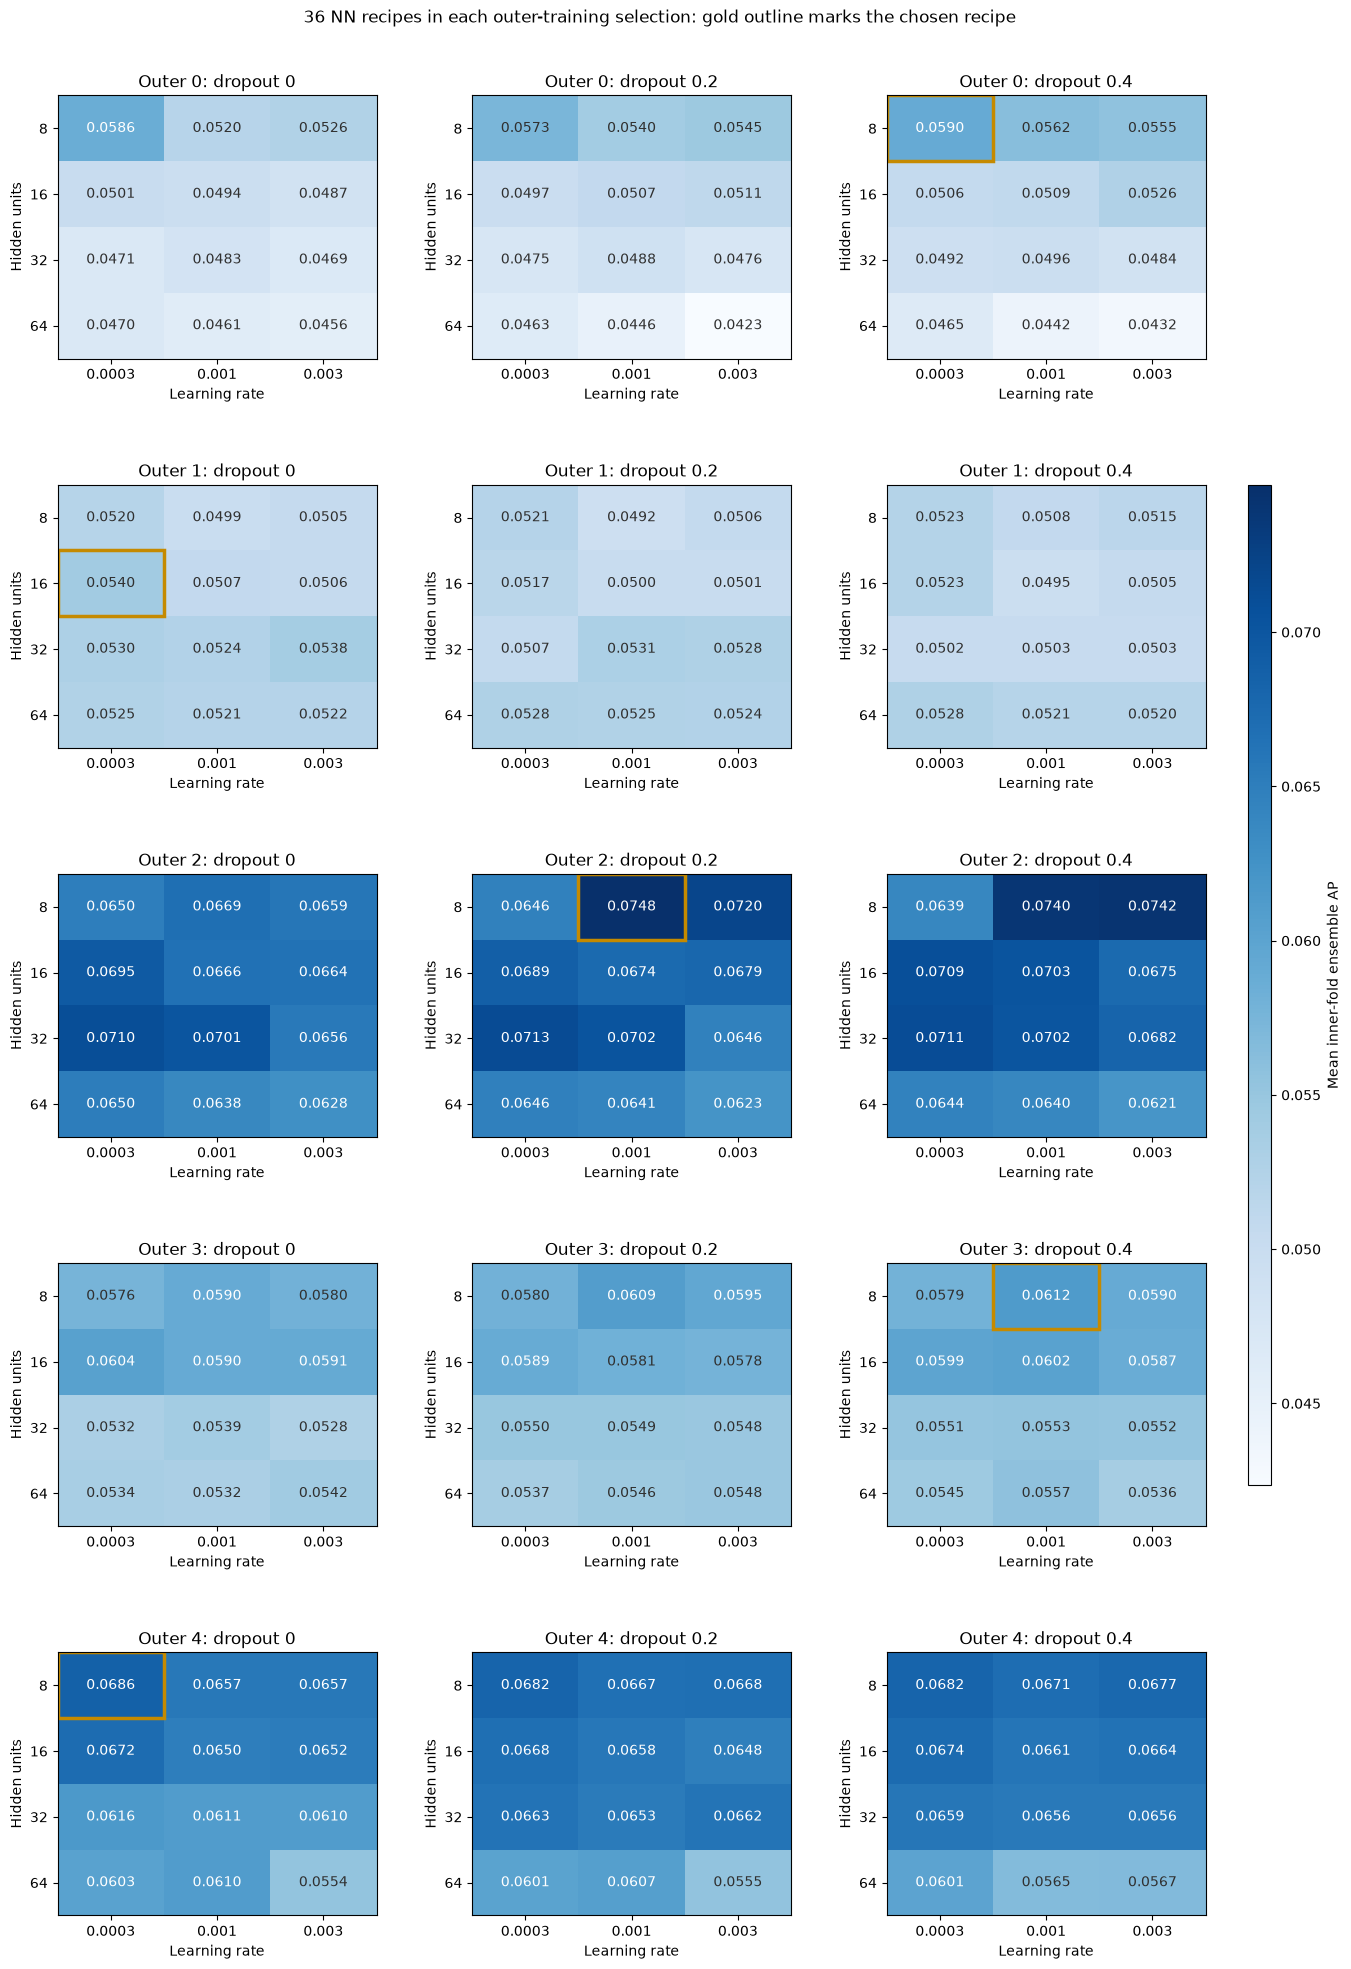

,condition,outer_fold,recipe_id,recipe_order,hidden_units,learning_rate,dropout,mean_inner_average_precision,std_inner_average_precision,inner_0_average_precision,inner_1_average_precision,inner_2_average_precision,selected
0,dedup_v1,0,r00,0,32,0.0010,0.2,0.048821,0.016227,0.027187,0.066268,0.053009,False
1,dedup_v1,0,r01,1,8,0.0003,0.0,0.058642,0.025559,0.031848,0.093050,0.051029,False
2,dedup_v1,0,r02,2,8,0.0003,0.2,0.057313,0.023653,0.032461,0.089130,0.050348,False
3,dedup_v1,0,r03,3,8,0.0003,0.4,0.059030,0.025442,0.033536,0.093765,0.049789,True
4,dedup_v1,0,r04,4,8,0.0010,0.0,0.051958,0.018694,0.029445,0.075218,0.051212,False
5,dedup_v1,0,r05,5,8,0.0010,0.2,0.053963,0.019455,0.028441,0.075625,0.057825,False
6,dedup_v1,0,r06,6,8,0.0010,0.4,0.056206,0.020702,0.028521,0.078298,0.061799,False
7,dedup_v1,0,r07,7,8,0.0030,0.0,0.052557,0.019430,0.029562,0.077081,0.051027,False
8,dedup_v1,0,r08,8,8,0.0030,0.2,0.054535,0.019895,0.028515,0.076815,0.058276,False
9,dedup_v1,0,r09,9,8,0.0030,0.4,0.055519,0.020563,0.028910,0.078982,0.058667,False


Showing 36 of 180 rows; the complete table is saved with the run.

In [5]:
render_section(report, 'tuning_candidates')

### 5. Check how often the same settings are selected

The first table records the choice within each outer-training group. The second counts how often the same combination wins. Similar choices across folds would suggest that the preferred settings are less sensitive to the training sample. Different choices can still work, but they give less support for adopting one fixed tuned combination.

The inner best AP is the score used to make a choice. It can favour a lucky setting and should not be read as the final performance estimate; use the outer scores below for that.


,outer_fold,model,mean_inner_average_precision,candidate_index,parameters,condition,provenance
0,0,spline,0.0535,2,"{""classifier__C"": 0.1, ""preprocessor__smooth_a...",dedup_v1,reused_clean_classical
1,0,random_forest,0.0469,1,"{""classifier__max_depth"": 4, ""classifier__max_...",dedup_v1,reused_clean_classical
2,0,xgboost,0.0458,6,"{""classifier__learning_rate"": 0.05, ""classifie...",dedup_v1,reused_clean_classical
3,1,spline,0.0650,2,"{""classifier__C"": 0.1, ""preprocessor__smooth_a...",dedup_v1,reused_clean_classical
4,1,random_forest,0.0629,9,"{""classifier__max_depth"": null, ""classifier__m...",dedup_v1,reused_clean_classical
5,1,xgboost,0.0547,2,"{""classifier__learning_rate"": 0.03, ""classifie...",dedup_v1,reused_clean_classical
6,2,spline,0.0773,7,"{""classifier__C"": 1.0, ""preprocessor__smooth_a...",dedup_v1,reused_clean_classical
7,2,random_forest,0.0728,2,"{""classifier__max_depth"": 4, ""classifier__max_...",dedup_v1,reused_clean_classical
8,2,xgboost,0.0760,8,"{""classifier__learning_rate"": 0.1, ""classifier...",dedup_v1,reused_clean_classical
9,3,spline,0.0605,3,"{""classifier__C"": 0.1, ""preprocessor__smooth_a...",dedup_v1,reused_clean_classical


,model,parameters,outer_training_selections
0,random_forest,"{""classifier__max_depth"": 4, ""classifier__max_...",3
1,random_forest,"{""classifier__max_depth"": 4, ""classifier__max_...",1
2,random_forest,"{""classifier__max_depth"": null, ""classifier__m...",1
3,spline,"{""classifier__C"": 0.1, ""preprocessor__smooth_a...",3
4,spline,"{""classifier__C"": 0.1, ""preprocessor__smooth_a...",1
5,spline,"{""classifier__C"": 1.0, ""preprocessor__smooth_a...",1
6,xgboost,"{""classifier__learning_rate"": 0.03, ""classifie...",1
7,xgboost,"{""classifier__learning_rate"": 0.03, ""classifie...",1
8,xgboost,"{""classifier__learning_rate"": 0.05, ""classifie...",1
9,xgboost,"{""classifier__learning_rate"": 0.05, ""classifie...",1


,condition,outer_fold,recipe_id,recipe_order,hidden_units,learning_rate,dropout,mean_inner_average_precision,std_inner_average_precision,inner_0_average_precision,inner_1_average_precision,inner_2_average_precision,selection_margin
0,dedup_v1,0,r03,3,8,0.0003,0.4,0.059030,0.025442,0.033536,0.093765,0.049789,0.000388
1,dedup_v1,1,r10,10,16,0.0003,0.0,0.054008,0.011943,0.064141,0.037239,0.060643,0.000163
2,dedup_v1,2,r05,5,8,0.0010,0.2,0.074753,0.015286,0.092122,0.054922,0.077213,0.000565
3,dedup_v1,3,r06,6,8,0.0010,0.4,0.061249,0.006132,0.052683,0.066706,0.064358,0.000304
4,dedup_v1,4,r01,1,8,0.0003,0.0,0.068626,0.029450,0.057729,0.108888,0.039262,0.000378


,recipe_id,hidden_units,learning_rate,dropout,outer_training_selections
0,r01,8,0.0003,0.0,1
1,r03,8,0.0003,0.4,1
2,r05,8,0.0010,0.2,1
3,r06,8,0.0010,0.4,1
4,r10,16,0.0003,0.0,1


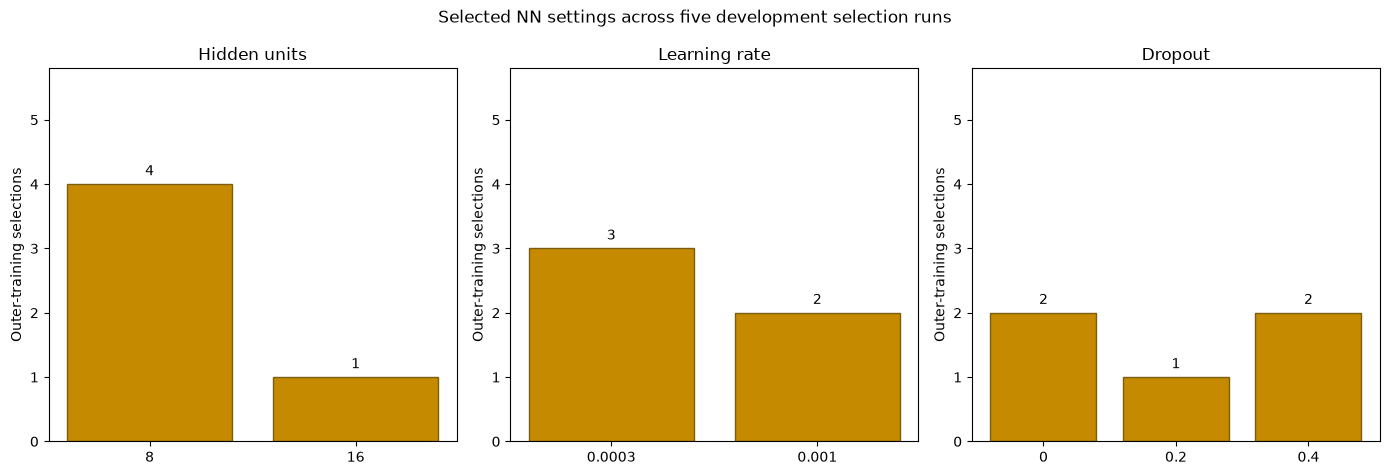

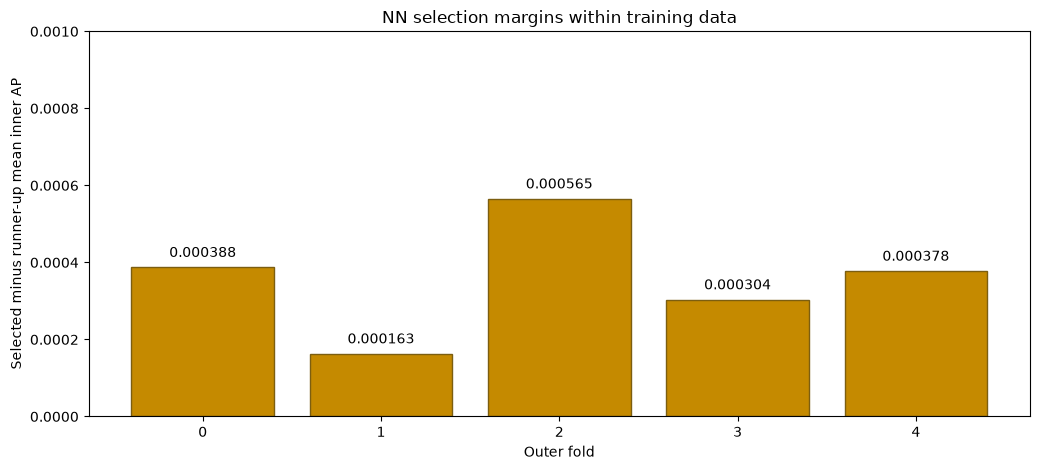

In [6]:
render_section(report, 'tuning_choices')

### Read selection margins and training duration

The margin is selected mean inner AP minus the runner-up's mean inner AP. A small margin shows that settings were close in this training sample; it is not a confidence interval. Selected epochs differ by training partition and seed. Executed and reused fit counts make the extra search effort visible.

,base_seed,outer_fold,training_seed,stop_fold,selected_epochs,stop_log_loss,attempted_stopping_epochs,outer_train_patients,score_patients,epoch_fit_patients,...,dropout,stage,inner_fold,provenance,stop_group,epoch_fit_images,epoch_stop_images,refit_images,refit_patients,score_images
339,42,0,42,NaN,83,0.0903,95,NaN,84,254,...,0.4,nn_outer_tuned,-1,NaN,1,3996,1366,5362,338,1344
340,142,0,142,NaN,100,0.0929,100,NaN,84,251,...,0.4,nn_outer_tuned,-1,NaN,2,4034,1328,5362,338,1344
341,242,0,242,NaN,100,0.0882,100,NaN,84,256,...,0.4,nn_outer_tuned,-1,NaN,3,3991,1371,5362,338,1344
666,42,1,43,NaN,98,0.0915,100,NaN,84,251,...,0.0,nn_outer_tuned,-1,NaN,2,4012,1328,5340,338,1366
667,142,1,143,NaN,85,0.0883,97,NaN,84,256,...,0.0,nn_outer_tuned,-1,NaN,3,3969,1371,5340,338,1366
668,242,1,243,NaN,58,0.0957,70,NaN,84,253,...,0.0,nn_outer_tuned,-1,NaN,4,4043,1297,5340,338,1366
993,42,2,44,NaN,95,0.0861,100,NaN,87,253,...,0.2,nn_outer_tuned,-1,NaN,3,4007,1371,5378,335,1328
994,142,2,144,NaN,26,0.0957,38,NaN,87,250,...,0.2,nn_outer_tuned,-1,NaN,4,4081,1297,5378,335,1328
995,242,2,244,NaN,89,0.0828,100,NaN,87,251,...,0.2,nn_outer_tuned,-1,NaN,0,4034,1344,5378,335,1328
1320,42,3,45,NaN,15,0.0958,27,NaN,82,255,...,0.4,nn_outer_tuned,-1,NaN,4,4038,1297,5335,340,1371


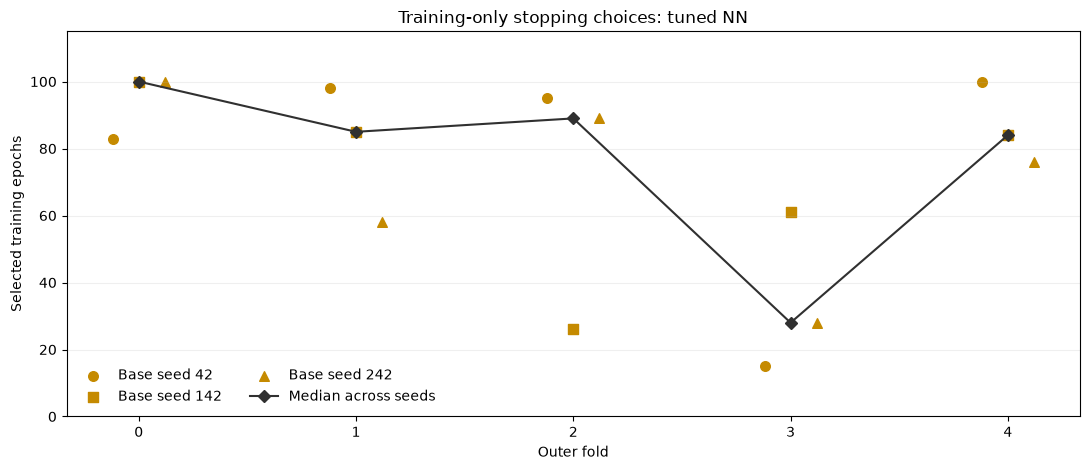

,stage,phase,fits,reused_fits
0,classical,reused_classical,0,660
1,nn_inner,refit,1620,0
2,nn_inner,stopping,1620,0
3,nn_outer_fixed_reused,reused_fixed_nn,0,30
4,nn_outer_tuned,refit,15,0
5,nn_outer_tuned,stopping,15,0


In [7]:
render_section(report, 'tuning_duration')

### 6. Compare the held-out results

The first table labels equal-fold primary and pooled secondary scores separately. The second shows AP changes within each fold. A positive "Tuned minus untuned" value favours tuning; a negative value favours the fixed model. Read the primary score, pooled secondary score and fold changes together so one favourable group does not hide inconsistent results.


,model,scope,average_precision,roc_auc,brier_score,log_loss,fold_ap_sd,fold_auc_sd
0,p_spline,mean_fold,0.0648,0.6556,0.0184,0.0910,0.0290,0.0896
1,p_spline,pooled,0.0492,0.6428,0.0184,0.0909,0.0290,0.0896
2,p_spline_tuned,mean_fold,0.0688,0.6430,0.0184,0.0912,0.0283,0.1029
3,p_spline_tuned,pooled,0.0502,0.6332,0.0184,0.0911,0.0283,0.1029
4,p_random_forest,mean_fold,0.0548,0.6032,0.0185,0.0919,0.0195,0.0651
5,p_random_forest,pooled,0.0433,0.6033,0.0184,0.0919,0.0195,0.0651
6,p_random_forest_tuned,mean_fold,0.0521,0.6267,0.0185,0.0922,0.0196,0.0754
7,p_random_forest_tuned,pooled,0.0406,0.6141,0.0185,0.0922,0.0196,0.0754
8,p_xgboost,mean_fold,0.0591,0.5930,0.0185,0.0939,0.0219,0.0914
9,p_xgboost,pooled,0.0434,0.5893,0.0185,0.0938,0.0219,0.0914


,model,outer_fold,fixed_average_precision,tuned_average_precision,average_precision_change,roc_auc_change
0,Spline logistic,0,0.0662,0.0687,0.0025,-0.0032
1,Random forest,0,0.0415,0.0390,-0.0025,0.0090
2,XGBoost,0,0.0522,0.0522,0.0000,0.0000
3,Metadata NN,0,0.0535,0.0591,0.0057,0.0107
4,Spline logistic,1,0.0460,0.0669,0.0209,-0.0365
5,Random forest,1,0.0559,0.0431,-0.0127,0.0199
6,XGBoost,1,0.0623,0.0610,-0.0013,-0.0075
7,Metadata NN,1,0.0575,0.0634,0.0059,-0.0034
8,Spline logistic,2,0.0373,0.0357,-0.0016,-0.0531
9,Random forest,2,0.0324,0.0320,-0.0004,0.0153


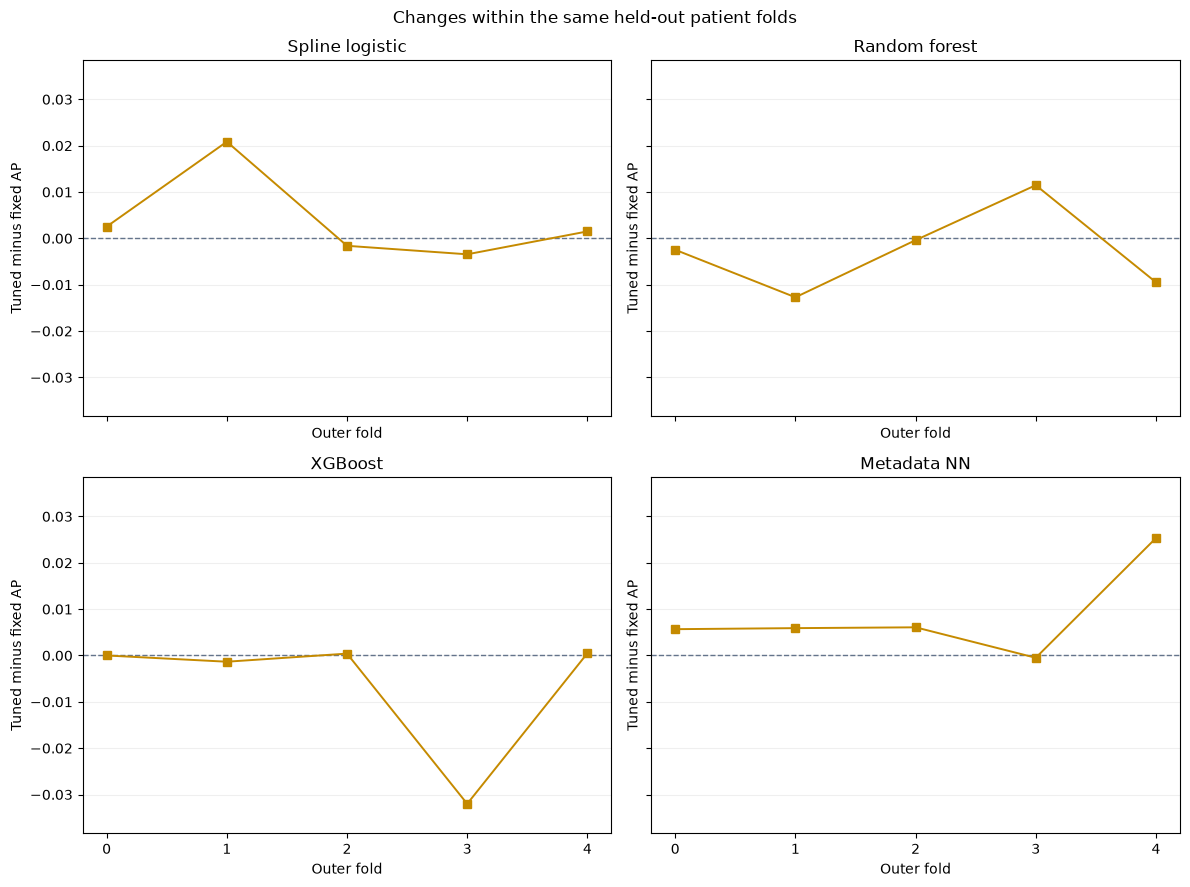

In [8]:
render_section(report, 'tuning_metrics')

### 7. Read the score comparison charts

The horizontal axis names model families. Blue bars use fixed settings; gold bars use settings selected within training. The first figure shows ROC-AUC vertically; the second shows AP. Higher bars are better, axes start at zero and annotations give exact scores.

Compare bars within each family, then compare the two measures. The direction and size of each change are calculated from the versioned predictions below; do not carry a historical direction into a new dataset. There are no uncertainty bars, so a small observed gain is not established as repeatable.


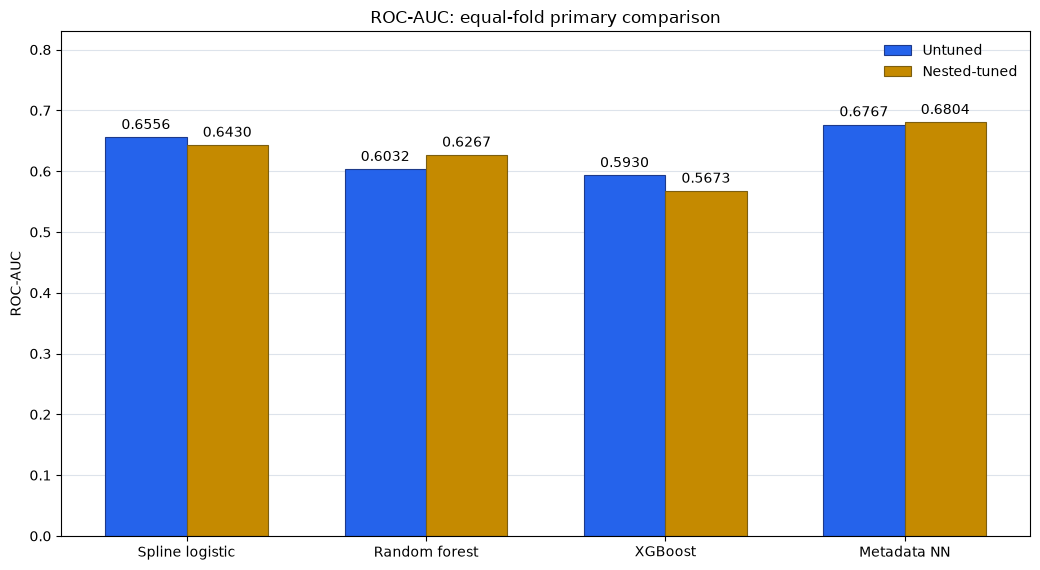

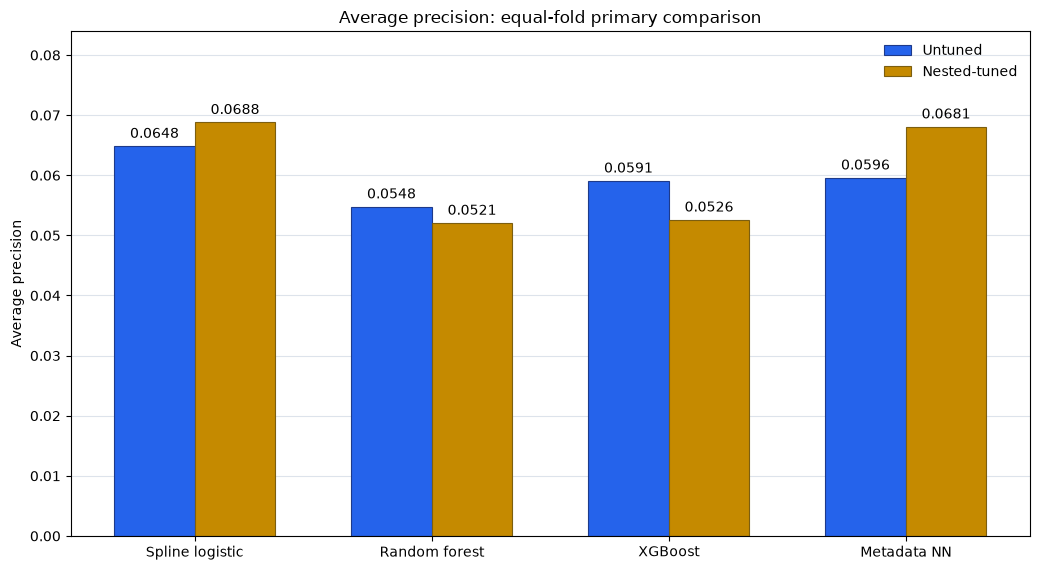

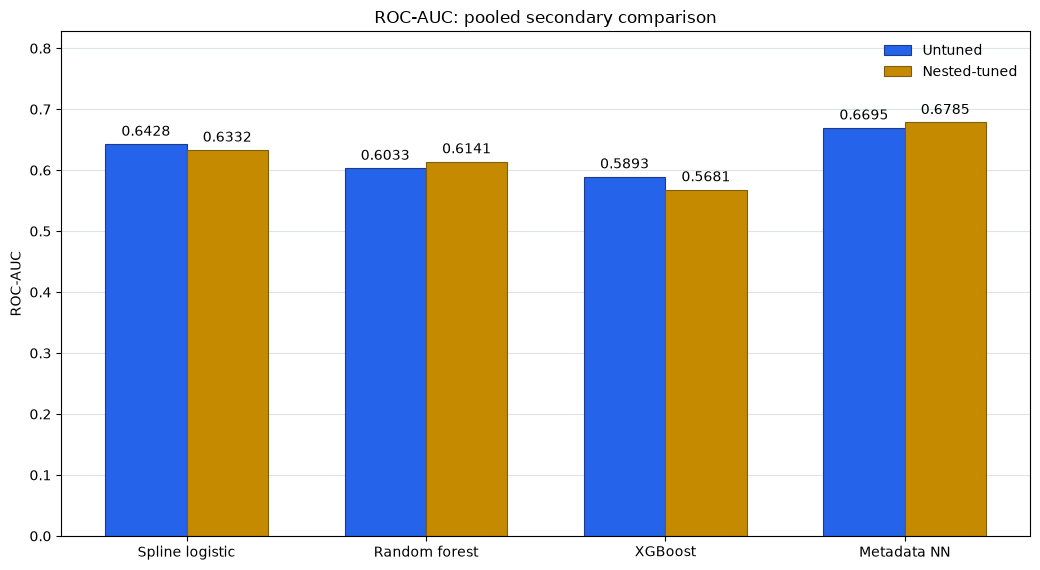

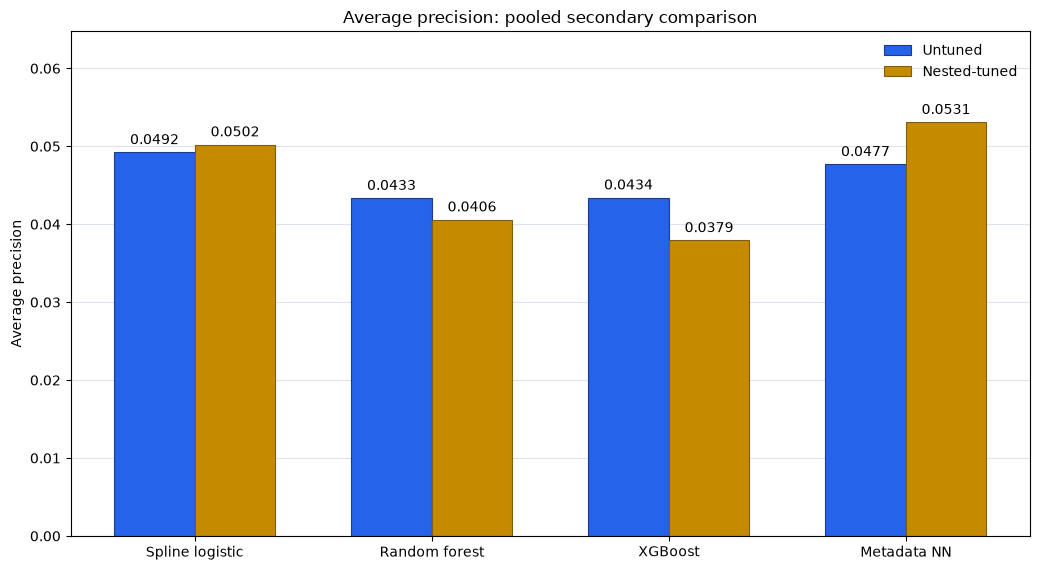

In [9]:
render_section(report, 'tuning_bars')

### 8. Read the ROC and precision-recall curves

Each row shows one model family. Blue dashed lines use the fixed settings and gold solid lines use the settings selected within training data.

On the left, the horizontal axis is the fraction of benign images wrongly flagged and the vertical axis is the fraction of malignant images found (recall). A curve nearer the upper-left corner is preferable; the grey dotted diagonal marks chance-level ranking.

On the right, the horizontal axis is recall and the vertical axis is precision, the fraction of flagged images that are malignant. A higher curve at the same recall means fewer false alarms among flagged images. The grey dotted line marks the observed malignant-image rate displayed in the figure. Precision is shown only from 0-30% to make these low values easier to compare.

The curves show where tuning helps or hurts across cutoffs. Crossing curves mean a version can perform better in one recall range and worse in another, even when one pooled score is higher.


The added fourth row is the metadata NN. Circle markers identify fixed settings and squares identify tuned settings, reinforcing the original blue/gold and dashed/solid encodings. Curves pool predictions and therefore complement the primary mean-fold scores.

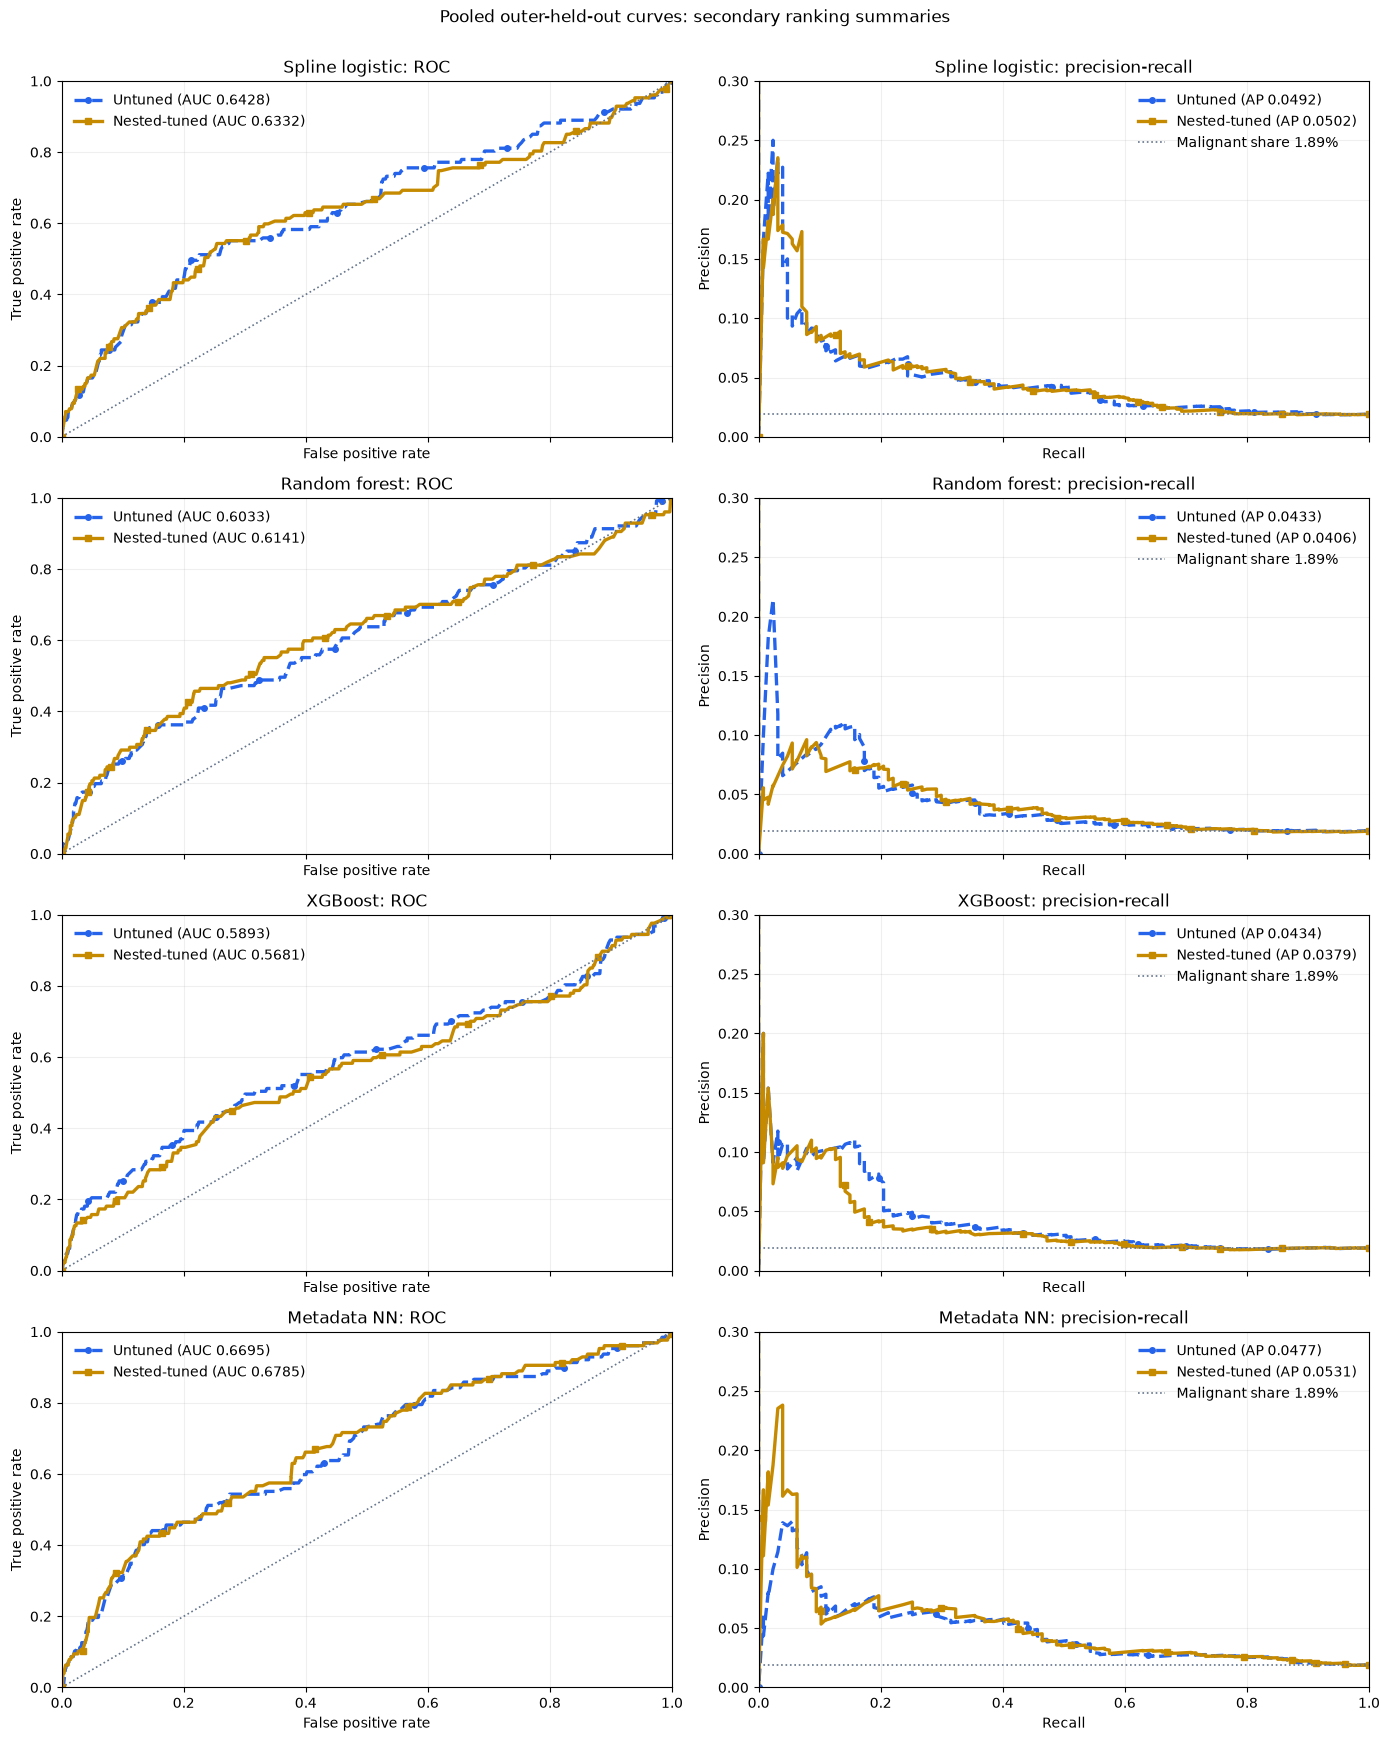

In [10]:
render_section(report, 'tuning_curves')

### 9. Collect the observed changes

The table puts pooled score changes beside the number of folds that improve, tie or worsen. Fold counts and score changes are computed for every family below. This is useful development evidence, but it does not establish a repeatable gain without an uncertainty check.


In [11]:
render_section(report, 'tuning_changes')

,model,scope,fixed_average_precision,tuned_average_precision,average_precision_change,fixed_roc_auc,tuned_roc_auc,roc_auc_change,folds_improved,folds_unchanged,folds_worse
0,Spline logistic,mean_fold,0.0648,0.0688,0.0040,0.6556,0.6430,-0.0126,3,0,2
1,Random forest,mean_fold,0.0548,0.0521,-0.0027,0.6032,0.6267,0.0235,1,0,4
2,XGBoost,mean_fold,0.0591,0.0526,-0.0065,0.5930,0.5673,-0.0257,2,1,2
3,Metadata NN,mean_fold,0.0596,0.0681,0.0085,0.6767,0.6804,0.0037,4,0,1


,model,scope,fixed_average_precision,tuned_average_precision,average_precision_change,fixed_roc_auc,tuned_roc_auc,roc_auc_change,folds_improved,folds_unchanged,folds_worse
0,Spline logistic,pooled,0.0492,0.0502,0.0010,0.6428,0.6332,-0.0097,3,0,2
1,Random forest,pooled,0.0433,0.0406,-0.0028,0.6033,0.6141,0.0108,1,0,4
2,XGBoost,pooled,0.0434,0.0379,-0.0055,0.5893,0.5681,-0.0212,2,1,2
3,Metadata NN,pooled,0.0477,0.0531,0.0054,0.6695,0.6785,0.0090,4,0,1


### Interpret paired differences on the primary measure

The additional assessment resamples whole patients within each preserved outer fold, using identical draws for every compared model. Two thousand draws estimate 95% intervals for tuned NN minus fixed NN, fixed spline and tuned spline. These comparisons use mean-fold AP as primary; secondary pooled results remain available in the assessment table. An interval spanning zero allows either direction under this assessment. It does not establish equivalence, nor account for all variability from retraining or expanding the search after earlier development results were examined. Read the paired comparison before treating a small score change as a reason to replace the final candidate.

,comparison,aggregation,metric,difference,ci_lower,ci_upper,bootstrap_replicates,valid_replicates,rejected_single_class_replicates,seed
0,nn_tuned minus fixed_nn,mean_fold,average_precision,0.008498,-0.001544,0.026211,2000,2000,0,42
1,nn_tuned minus fixed_nn,mean_fold,roc_auc,0.003699,-0.005046,0.012091,2000,2000,0,42
2,nn_tuned minus fixed_nn,mean_fold,log_loss,-0.000486,-0.001038,0.000149,2000,2000,0,42
3,nn_tuned minus fixed_nn,mean_fold,brier,-0.000026,-0.000064,0.000016,2000,2000,0,42
8,nn_tuned minus fixed_spline,mean_fold,average_precision,0.003227,-0.007651,0.014526,2000,2000,0,42
9,nn_tuned minus fixed_spline,mean_fold,roc_auc,0.024762,-0.002876,0.044875,2000,2000,0,42
10,nn_tuned minus fixed_spline,mean_fold,log_loss,-0.001323,-0.002842,0.000231,2000,2000,0,42
11,nn_tuned minus fixed_spline,mean_fold,brier,-0.000065,-0.000216,0.000092,2000,2000,0,42
16,nn_tuned minus tuned_spline,mean_fold,average_precision,-0.000740,-0.014043,0.006441,2000,2000,0,42
17,nn_tuned minus tuned_spline,mean_fold,roc_auc,0.037366,-0.006853,0.066187,2000,2000,0,42


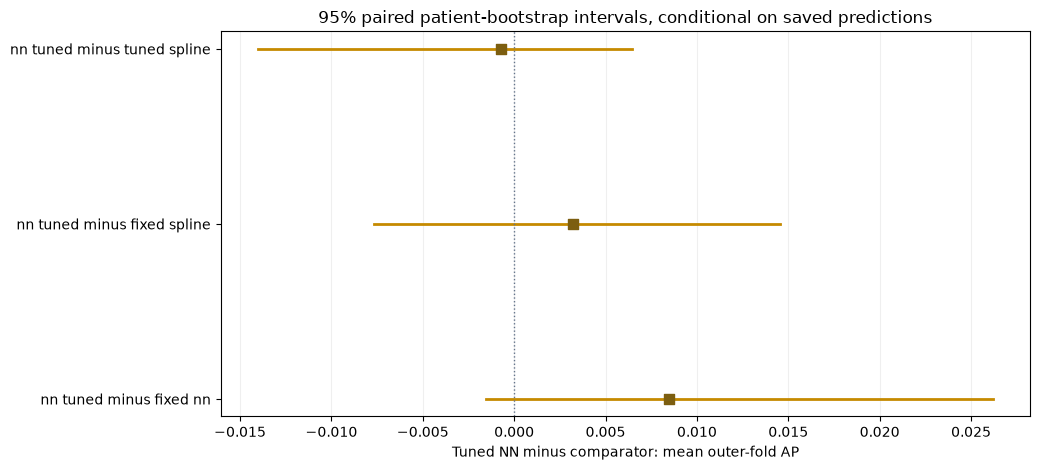

The interval uses the same whole-patient resampling draw for both models within each preserved outer fold. An interval spanning zero leaves both directions compatible with this conditional assessment; it does not prove equivalence.

In [12]:
render_section(report, 'tuning_intervals')

## Limitations

The search covers only the settings listed here. It cannot establish the best possible spline, tree or neural-network model. Different inner folds could select different settings, especially with only 127 malignant images from 88 patients. The added NN paired intervals condition on saved predictions and omit retraining and broader adaptive-selection variability. Any small gain must be interpreted with these limits; an interval spanning zero leaves its direction unresolved.

The nested design keeps each outer patient's labels outside their own settings search. However, the same outer folds have already guided broader model and feature choices. These results remain development evidence, and nested tuning cannot undo that earlier reuse.

Ranking improvements do not prove that probabilities are calibrated or that a cutoff is useful in practice. This notebook does not establish clinical safety, causation or performance on patients from another hospital. The reserved test set has not been used to evaluate these models.


The NN grid keeps weight decay, batch size, activation and depth fixed. It evaluates one hidden-layer family; wider networks, alternative optimizers, class weighting and additional engineered features remain outside scope. Settings-selection frequency and runner-up margins describe training sensitivity, not new-patient confidence intervals.

## Summary

The computed summary below states the fixed-to-tuned changes and fold consistency for spline logistic, Random Forest, XGBoost and the metadata NN. Their searches include the fixed settings, but selecting the best inner score can still reduce outer performance through sampling variability. A favourable point estimate alone does not establish a dependable gain or calibrated probabilities.

Do not choose an individual seed or a global recipe from the outer results after inspecting them. Any final candidate change requires the same paired uncertainty and practical trade-off review.

Next, use notebook 08 to check uncertainty, probability calibration, subgroup results and training-selected cutoffs for the retained model. Evaluate the reserved test only after the complete method is frozen.


Freezing the procedure means recording the complete data cleaning, feature transformation, model or search recipe, seed averaging, stopping, calibration and threshold rules before final testing. The final model is then trained using development data according to those rules, and the reserved test is evaluated once. Changing a rule after seeing its test result would make that test part of development rather than an independent final check. That final-fit and test stage is not performed here.

In [13]:
render_section(report, 'tuning_summary')

**Spline logistic:** mean-fold AP 0.0648 → 0.0688 (+0.0040); 3/5 folds improve. Pooled AP 0.0492 → 0.0502.

**Random forest:** mean-fold AP 0.0548 → 0.0521 (-0.0027); 1/5 folds improve. Pooled AP 0.0433 → 0.0406.

**XGBoost:** mean-fold AP 0.0591 → 0.0526 (-0.0065); 2/5 folds improve. Pooled AP 0.0434 → 0.0379.

**Metadata NN:** mean-fold AP 0.0596 → 0.0681 (+0.0085); 4/5 folds improve. Pooled AP 0.0477 → 0.0531.

The comparison estimates each training-and-selection procedure. Selected settings can differ between folds; this does not yet specify one all-development recipe. Small gains and inner selection margins are not sampling confidence intervals. Keep the final model decision separate from reporting these development results and freeze preprocessing, recipe selection, calibration, cutoff rules and evaluation before opening the reserved test.